# 07. Raman Spectroscopy Denoising with Spatial Median Filter + sklearn NMF

**Objective:** Apply a simple, effective two-stage denoising pipeline:
1. **3×3 Spatial Median Filter** - Remove spatial outliers (cosmic rays, noise spikes)
2. **Non-negative Matrix Factorization (sklearn)** - Learn low-rank signal structure

This is a clean, minimal pipeline that works well in practice.

## Setup: Imports and Configuration

In [ ]:
from ast import Lambda
import sys
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import median_filter
from sklearn.decomposition import NMF
from sklearn.mixture import GaussianMixture
import warnings
warnings.filterwarnings('ignore')

# Add project root to path
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.append(project_root)



 Loaded wavenumbers from RamanFreqTable.csv
  Wavenumber range: [1.0, 1738.0] cm^-1
Project Root: c:\Users\Andrei\incdsb\New folder\glioma-synthetic-data
Raw Data Dir: C:\Users\Andrei\incdsb\New folder\glioma-synthetic-data\data\raw


In [3]:

# Load wavenumbers

calib_path = Path("../data/RamanFreqTable.csv")
if calib_path.exists():
    calib_df = pd.read_csv(calib_path)
    wavenumbers = calib_df.iloc[:, 1].values  # Second column contains wavenumbers
    print(f"\n Loaded wavenumbers from {calib_path.name}")
    print(f"  Wavenumber range: [{wavenumbers.min():.1f}, {wavenumbers.max():.1f}] cm^-1")
else:
    print(f" Calibration file not found at {calib_path}")
    wavenumbers = np.arange(Lambda)

# Configuration
RAW_DATA_DIR = Path("../data/raw")
SIGNAL_LENGTH = 1738

print(f"Project Root: {project_root}")
print(f"Raw Data Dir: {RAW_DATA_DIR.resolve()}")


 Loaded wavenumbers from RamanFreqTable.csv
  Wavenumber range: [50.0, 3399.8] cm^-1
Project Root: c:\Users\Andrei\incdsb\New folder\glioma-synthetic-data
Raw Data Dir: C:\Users\Andrei\incdsb\New folder\glioma-synthetic-data\data\raw


## 1. Load Hyperspectral Data Slide

Found 59 raw data files

Loading: HF-1293_13_1.h5_0.npy
Raw data shape: (247, 31, 1738)
Data type: float32
Intensity range: [-17081.7, 34138.3]

Spatial dimensions: (247, 31)
Spectral channels: 1738
Total spectra: 7657


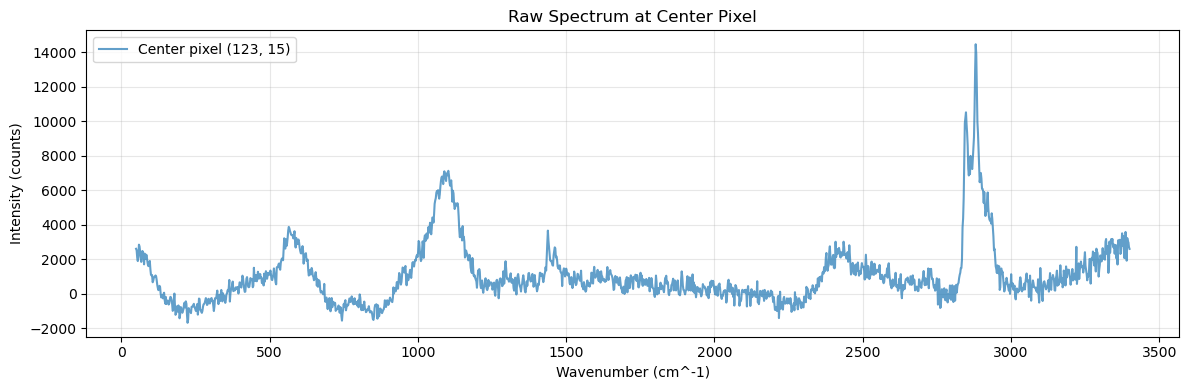

In [6]:
# Find and load the first available biopsy slide
raw_files = sorted(list(RAW_DATA_DIR.rglob("*.npy")))
print(f"Found {len(raw_files)} raw data files")

# Load first file as (X, Y, Lambda) tensor
data_file = raw_files[0]
print(f"\nLoading: {data_file.name}")

data_cube_raw = np.load(data_file)
print(f"Raw data shape: {data_cube_raw.shape}")
print(f"Data type: {data_cube_raw.dtype}")
print(f"Intensity range: [{np.min(data_cube_raw):.1f}, {np.max(data_cube_raw):.1f}]")

X, Y, Lambda = data_cube_raw.shape
print(f"\nSpatial dimensions: ({X}, {Y})")
print(f"Spectral channels: {Lambda}")
print(f"Total spectra: {X * Y}")

# Visualize sample spectrum at center pixel
center_x, center_y = X // 2, Y // 2
sample_spectrum_raw = data_cube_raw[center_x, center_y, :]
plt.figure(figsize=(12, 4))
plt.plot(wavenumbers, sample_spectrum_raw, label=f"Center pixel ({center_x}, {center_y})", alpha=0.7)
plt.xlabel("Wavenumber (cm^-1)")
plt.ylabel("Intensity (counts)")
plt.title("Raw Spectrum at Center Pixel")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Spatial 3×3 Median Filter

In [7]:
print("Applying 3×3 spatial median filter...")
data_cube_median = np.zeros_like(data_cube_raw)

# Apply 3x3 spatial median independently per wavelength
for wavelength_idx in range(Lambda):
    spatial_slice = data_cube_raw[:, :, wavelength_idx]
    filtered_slice = median_filter(spatial_slice, size=3, mode='reflect')
    data_cube_median[:, :, wavelength_idx] = filtered_slice
    
    if (wavelength_idx + 1) % 200 == 0:
        print(f"  Processed {wavelength_idx + 1}/{Lambda} wavelengths")

print(f" Median filtering complete")
print(f"  Before: [{data_cube_raw.min():.1f}, {data_cube_raw.max():.1f}]")
print(f"  After:  [{data_cube_median.min():.1f}, {data_cube_median.max():.1f}]")

# Flatten for NMF
data_flat = data_cube_raw.reshape(X * Y, Lambda)
data_flat_median = data_cube_median.reshape(X * Y, Lambda)

print(f"\nFlattened shapes:")
print(f"  Raw: {data_flat.shape}")
print(f"  Median-filtered: {data_flat_median.shape}")

Applying 3×3 spatial median filter...
  Processed 200/1738 wavelengths
  Processed 400/1738 wavelengths
  Processed 600/1738 wavelengths
  Processed 800/1738 wavelengths
  Processed 1000/1738 wavelengths
  Processed 1200/1738 wavelengths
  Processed 1400/1738 wavelengths
  Processed 1600/1738 wavelengths
 Median filtering complete
  Before: [-17081.7, 34138.3]
  After:  [-4620.3, 30468.9]

Flattened shapes:
  Raw: (7657, 1738)
  Median-filtered: (7657, 1738)


## 4. Non-negative Matrix Factorization (sklearn)

In [4]:
print("\n" + "="*80)
print("FITTING NMF USING SKLEARN")
print("="*80)

# Ensure non-negativity and normalize
data_smooth = data_flat_median - np.min(data_flat_median) + 1e-8  # Shift to make non-negative
global_max = np.percentile(data_smooth, 99.9)
data_normalized = np.clip(data_smooth / global_max, 0, 1)

print(f"\nPreparing data for NMF...")
print(f"  Normalized range: [{data_normalized.min():.4f}, {data_normalized.max():.4f}]")
print(f"  All non-negative: {np.all(data_normalized >= 0)}")

# Fit NMF
print(f"\nFitting NMF (100 components, 500 iterations)...")
nmf_model = NMF(
    n_components=100,
    init='nndsvda',
    max_iter=500,
    random_state=42,
    verbose=1
)

W_nmf = nmf_model.fit_transform(data_normalized)
H_nmf = nmf_model.components_

print(f"\n NMF fit complete!")
print(f"  W shape (abundance): {W_nmf.shape}")
print(f"  H shape (basis): {H_nmf.shape}")
print(f"  Final reconstruction error: {nmf_model.reconstruction_err_:.2e}")

# Reconstruct
print(f"\nReconstructing denormalized spectra...")
X_recon_norm = W_nmf @ H_nmf
X_recon_denorm = X_recon_norm * global_max

print(f"  Reconstruction range: [{X_recon_denorm.min():.1f}, {X_recon_denorm.max():.1f}]")
print(f"   Reconstruction complete!")


FITTING NMF USING SKLEARN

Preparing data for NMF...
  Normalized range: [0.0000, 1.0000]
  All non-negative: True

Fitting NMF (100 components, 500 iterations)...
violation: 1.0
violation: 0.009757449766241976
violation: 0.009524655549420346
violation: 0.010474483170718705
violation: 0.008510264652596765
violation: 0.0073762550806392895
violation: 0.006167557398637098
violation: 0.005363123713249659
violation: 0.00478362699186023
violation: 0.004322375680567451
violation: 0.0039485300388308175
violation: 0.0036573107338837003
violation: 0.0034366605636932204
violation: 0.0032533359673574663
violation: 0.003097620685195937
violation: 0.0029670429390135566
violation: 0.002844036377126841
violation: 0.002739506704378922
violation: 0.0026344104194468624
violation: 0.002542771022097472
violation: 0.0024599332774425937
violation: 0.002382832283361971
violation: 0.002310028011276673
violation: 0.0022441613477365697
violation: 0.0021793079668223814
violation: 0.002119361009526059
violation: 


HISTOGRAM: Maximum Intensity Values in Normalized Data

Statistics of spectrum max values:
  Min:    0.3444
  Max:    1.0000
  Mean:   0.9172
  Median: 1.0000
  Std:    0.1649

✓ Saved: normalized_max_intensity_histogram.png


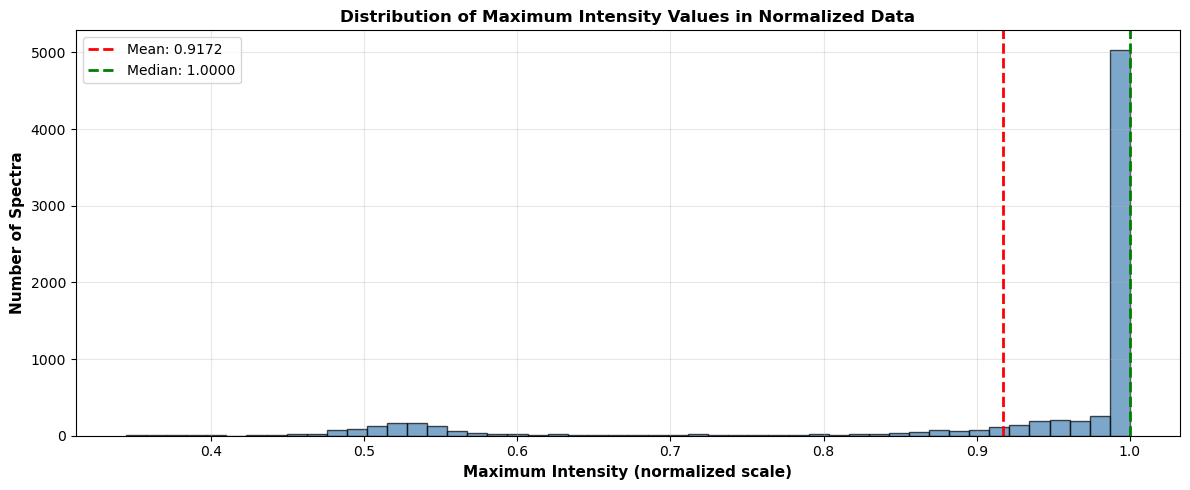


✓ Histogram analysis complete!


In [6]:
print("\n" + "="*80)
print("HISTOGRAM: Maximum Intensity Values in Normalized Data")
print("="*80)

# Compute max value for each spectrum
max_values = np.max(data_normalized, axis=1)

print(f"\nStatistics of spectrum max values:")
print(f"  Min:    {np.min(max_values):.4f}")
print(f"  Max:    {np.max(max_values):.4f}")
print(f"  Mean:   {np.mean(max_values):.4f}")
print(f"  Median: {np.median(max_values):.4f}")
print(f"  Std:    {np.std(max_values):.4f}")

# Create histogram
fig, ax = plt.subplots(figsize=(12, 5))
ax.hist(max_values, bins=50, color='steelblue', alpha=0.7, edgecolor='black')
ax.axvline(np.mean(max_values), color='red', linestyle='--', linewidth=2, label=f'Mean: {np.mean(max_values):.4f}')
ax.axvline(np.median(max_values), color='green', linestyle='--', linewidth=2, label=f'Median: {np.median(max_values):.4f}')
ax.set_xlabel('Maximum Intensity (normalized scale)', fontsize=11, fontweight='bold')
ax.set_ylabel('Number of Spectra', fontsize=11, fontweight='bold')
ax.set_title('Distribution of Maximum Intensity Values in Normalized Data', fontsize=12, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('normalized_max_intensity_histogram.png', dpi=100, bbox_inches='tight')
print("\n Saved: normalized_max_intensity_histogram.png")
plt.show()

print(f"\n Histogram analysis complete!")


MASK: Spectra with Max < 0.6 and Biological RGB Visualization

Mask statistics:
  Total pixels: 7657
  Weak signal pixels (max < 0.6): 990
  Percentage weak: 12.9%

Generating biological RGB visualization...
  RGB image shape: (247, 31, 3)
  Range per channel: [0.0000, 1.0000]
  Channels: R=Phenylalanine (990-1020), G=C-H Stretch (2800-3000), B=CH2 (1430-1460)

GMM CLUSTERING: Filter Strong Signals & Apply Gaussian Mixture Model

Signal partitioning:
  Strong signal spectra (max >= 0.6): 6667 (87.1%)
  Weak signal spectra (max < 0.6): 990 (12.9%)

Filtered W matrix:
  Original shape: (7657, 100)
  Filtered shape: (6667, 100)
  Min abundance: 0.0000
  Max abundance: 0.2909

Fitting Gaussian Mixture Model (3 components)...
✓ GMM fit complete
  Log-likelihood: 542.2026
  BIC: -7093676.29
  Component weights: [0.02209699 0.2061222  0.77178085]

Soft labels shape: (6667, 3)
  Component 0 probability: mean=0.0218, std=0.1454
  Component 1 probability: mean=0.2056, std=0.3906
  Component 2 p

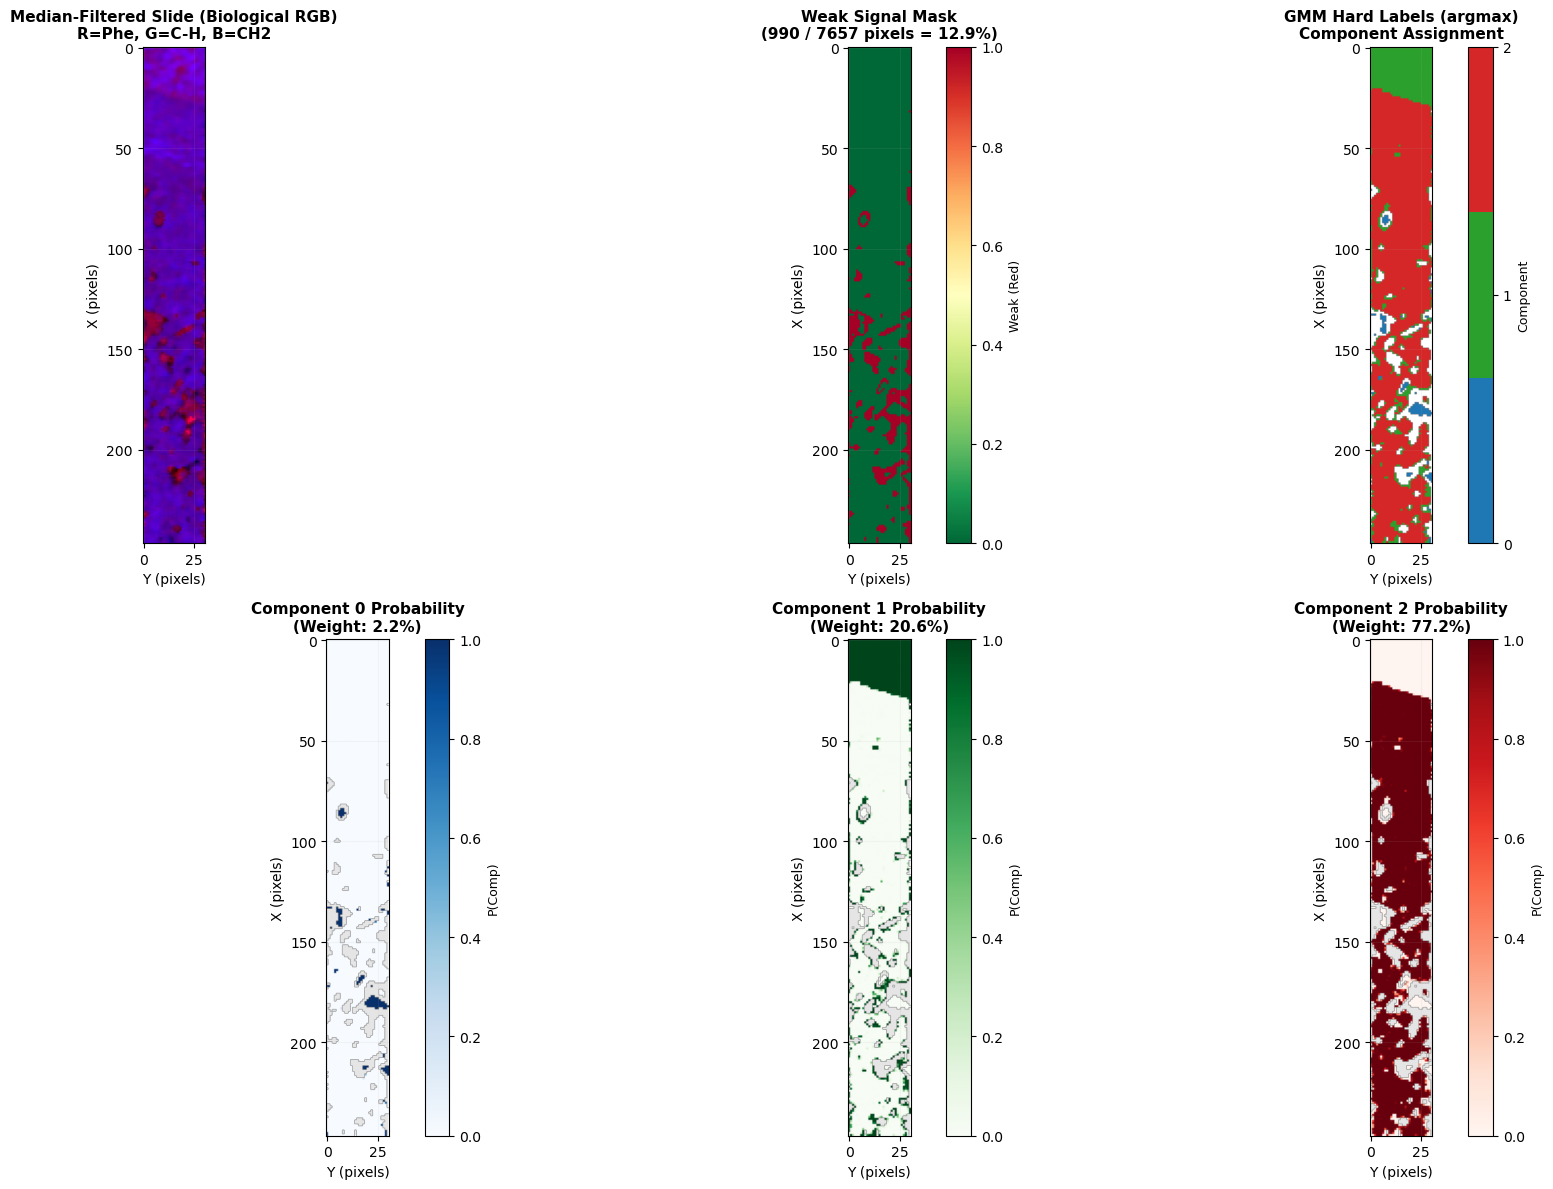


✓ GMM clustering visualization complete!


In [20]:
from matplotlib.colors import ListedColormap


print("\n" + "="*80)
print("MASK: Spectra with Max < 0.6 and Biological RGB Visualization")
print("="*80)

# Create mask of spectra with max < 0.6
mask_weak = np.max(data_normalized, axis=1) < 0.6
mask_image = mask_weak.reshape(X, Y)

print(f"\nMask statistics:")
print(f"  Total pixels: {X * Y}")
print(f"  Weak signal pixels (max < 0.6): {np.sum(mask_weak)}")
print(f"  Percentage weak: {100 * np.sum(mask_weak) / (X * Y):.1f}%")


# Define biological RGB visualization function
def raman_to_bio_rgb(hsi_cube, wavenumbers):
    """
    Converts a Raman Hyperspectral Cube to a 'False Color' RGB image 
    highlighting biological markers.
    
    Args:
        hsi_cube: (H, W, D) Raw or Preprocessed Data
        wavenumbers: (D,) Vector of cm^-1 values
    
    Returns:
        rgb_img: (H, W, 3) Normalized image for display
    """
    H, W, D = hsi_cube.shape
    
    # --- 1. Define Marker Indices ---
    # RED Channel: Phenylalanine (1004 cm^-1) - The "Sharp" Marker
    idx_phe_start = np.argmin(np.abs(wavenumbers - 990))
    idx_phe_end   = np.argmin(np.abs(wavenumbers - 1020))
    
    # GREEN Channel: C-H Stretch (2850-2950 cm^-1) - The "Massive" Marker (Lipids)
    idx_hwn_start = np.argmin(np.abs(wavenumbers - 2800))
    idx_hwn_end   = np.argmin(np.abs(wavenumbers - 3000))
    
    # BLUE Channel: CH2 Deformation (1430-1450 cm^-1) - General Organic
    idx_ch2_start = np.argmin(np.abs(wavenumbers - 1430))
    idx_ch2_end   = np.argmin(np.abs(wavenumbers - 1460))
    
    # --- 2. Extract Bands (Integration/Sum) ---
    # We sum the area under the peak (more robust than single pixel)
    R = np.sum(hsi_cube[:, :, idx_phe_start:idx_phe_end], axis=2)
    G = np.sum(hsi_cube[:, :, idx_hwn_start:idx_hwn_end], axis=2)
    B = np.sum(hsi_cube[:, :, idx_ch2_start:idx_ch2_end], axis=2)
    
    # --- 3. Normalize per Channel (Contrast Stretch) ---
    # This ensures weak signals don't disappear
    def norm(c):
        c = c - np.min(c)
        return c / (np.max(c) + 1e-8)
    
    R = norm(R)
    G = norm(G)
    B = norm(B)
    
    # --- 4. Stack ---
    rgb_img = np.stack([R, G, B], axis=-1)
    
    # Boost gamma for visibility (optional)
    rgb_img = np.power(rgb_img, 0.8) 
    
    return rgb_img

# Generate biological RGB image
print(f"\nGenerating biological RGB visualization...")
rgb_normalized = raman_to_bio_rgb(data_cube_median, wavenumbers)

print(f"  RGB image shape: {rgb_normalized.shape}")
print(f"  Range per channel: [{rgb_normalized.min():.4f}, {rgb_normalized.max():.4f}]")
print(f"  Channels: R=Phenylalanine (990-1020), G=C-H Stretch (2800-3000), B=CH2 (1430-1460)")



print("\n" + "="*80)
print("GMM CLUSTERING: Filter Strong Signals & Apply Gaussian Mixture Model")
print("="*80)




# Create mask of STRONG signal spectra (inverse of weak mask)
mask_strong = np.max(data_normalized, axis=1) >= 0.6
mask_weak = ~mask_strong
n_strong = np.sum(mask_strong)
n_weak = np.sum(mask_weak)

print(f"\nSignal partitioning:")
print(f"  Strong signal spectra (max >= 0.6): {n_strong} ({100*n_strong/(X*Y):.1f}%)")
print(f"  Weak signal spectra (max < 0.6): {n_weak} ({100*n_weak/(X*Y):.1f}%)")

# Filter W_nmf to keep only strong signal spectra
W_strong = W_nmf[mask_strong, :]

print(f"\nFiltered W matrix:")
print(f"  Original shape: {W_nmf.shape}")
print(f"  Filtered shape: {W_strong.shape}")
print(f"  Min abundance: {W_strong.min():.4f}")
print(f"  Max abundance: {W_strong.max():.4f}")

# Fit GMM with 3 components
print(f"\nFitting Gaussian Mixture Model (3 components)...")
gmm = GaussianMixture(n_components=3, random_state=42, n_init=10)
gmm.fit(W_strong)

print(f" GMM fit complete")
print(f"  Log-likelihood: {gmm.score(W_strong):.4f}")
print(f"  BIC: {gmm.bic(W_strong):.2f}")
print(f"  Component weights: {gmm.weights_}")

# Get soft labels (probabilities) for each component
# predict_proba returns (n_samples, 3) array of probabilities for each component
soft_labels = gmm.predict_proba(W_strong)

print(f"\nSoft labels shape: {soft_labels.shape}")
print(f"  Component 0 probability: mean={soft_labels[:, 0].mean():.4f}, std={soft_labels[:, 0].std():.4f}")
print(f"  Component 1 probability: mean={soft_labels[:, 1].mean():.4f}, std={soft_labels[:, 1].std():.4f}")
print(f"  Component 2 probability: mean={soft_labels[:, 2].mean():.4f}, std={soft_labels[:, 2].std():.4f}")

# Create spatial maps for each component
spatial_soft_labels_components = []
component_names = ['Component 0', 'Component 1', 'Component 2']
component_colors = ['Blues', 'Greens', 'Reds']  # Distinct color schemes

for comp_idx in range(3):
    # Initialize with NaN for weak signal pixels
    spatial_soft_labels = np.full(X * Y, np.nan)
    
    # Place soft labels in their original pixel locations
    spatial_soft_labels[mask_strong] = soft_labels[:, comp_idx]
    
    # Reshape to spatial grid (X, Y)
    spatial_soft_labels_image = spatial_soft_labels.reshape(X, Y)
    spatial_soft_labels_components.append(spatial_soft_labels_image)
    
    print(f"\n{component_names[comp_idx]} spatial map:")
    print(f"  Valid pixels: {np.sum(~np.isnan(spatial_soft_labels_image))}")
    print(f"  Range (non-NaN): [{np.nanmin(spatial_soft_labels_image):.4f}, {np.nanmax(spatial_soft_labels_image):.4f}]")

# Create 5-panel visualization: RGB + Mask + 3 Components
component_colors_plot = ['#1f77b4', '#2ca02c', '#d62728']  # Blue, Green, Red


fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

# Top-Left: Biological RGB image
ax = axes[0]
ax.imshow(rgb_normalized)
ax.set_title(f'Median-Filtered Slide (Biological RGB)\nR=Phe, G=C-H, B=CH2', 
             fontsize=11, fontweight='bold')
ax.set_xlabel('Y (pixels)', fontsize=10)
ax.set_ylabel('X (pixels)', fontsize=10)
ax.grid(True, alpha=0.1)

# Top-Middle: Weak signal mask
ax = axes[1]
im = ax.imshow(mask_image, cmap='RdYlGn_r', vmin=0, vmax=1)
ax.set_title(f'Weak Signal Mask\n({n_weak} / {X*Y} pixels = {100*n_weak/(X*Y):.1f}%)', 
             fontsize=11, fontweight='bold')
ax.set_xlabel('Y (pixels)', fontsize=10)
ax.set_ylabel('X (pixels)', fontsize=10)
ax.grid(True, alpha=0.1)
cbar = plt.colorbar(im, ax=ax)
cbar.set_label('Weak (Red)', fontsize=9)

# Top-Right: Combined 3-component label (argmax)
ax = axes[2]
# Compute hard labels (argmax of soft labels)
hard_labels = np.full(X * Y, np.nan)
hard_labels[mask_strong] = np.argmax(soft_labels, axis=1)
hard_labels_image = hard_labels.reshape(X, Y)

# plot hard labels with distinct colors for each component, colors=component_colors_plot
component_cmap = ListedColormap(component_colors_plot)

im = ax.imshow(hard_labels_image, cmap=component_cmap)
ax.set_title(f'GMM Hard Labels (argmax)\nComponent Assignment', 
             fontsize=11, fontweight='bold')
ax.set_xlabel('Y (pixels)', fontsize=10)
ax.set_ylabel('X (pixels)', fontsize=10)
ax.grid(True, alpha=0.1)
cbar = plt.colorbar(im, ax=ax, ticks=[0, 1, 2])
cbar.set_label('Component', fontsize=9)

# Bottom row: Three component probability maps (will update titles after tissue ID)
for comp_idx in range(3):
    ax = axes[3 + comp_idx]
    im = ax.imshow(spatial_soft_labels_components[comp_idx], cmap=component_colors[comp_idx], vmin=0, vmax=1)
    ax.set_title(f'{component_names[comp_idx]} Probability\n(Weight: {gmm.weights_[comp_idx]:.1%})', 
                 fontsize=11, fontweight='bold')
    ax.set_xlabel('Y (pixels)', fontsize=10)
    ax.set_ylabel('X (pixels)', fontsize=10)
    ax.grid(True, alpha=0.1)
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label('P(Comp)', fontsize=9)
    
    # Add mask overlay to show missing pixels
    missing_mask = np.isnan(spatial_soft_labels_components[comp_idx])
    if np.any(missing_mask):
        ax.contourf(np.arange(Y), np.arange(X), missing_mask.astype(float), 
                    levels=[0.5, 1.5], colors=['gray'], alpha=0.2)

plt.tight_layout()
plt.savefig('gmm_soft_labels_3components.png', dpi=100, bbox_inches='tight')
print("\n Saved: gmm_soft_labels_3components.png")
plt.show()

print(f"\n GMM clustering visualization complete!")



TISSUE TYPE IDENTIFICATION & COLOR MAPPING
✓ Loaded wavenumber calibration

Computing mean spectra for tissue identification...
  Component 0: 145 pixels
  Component 1: 1349 pixels
  Component 2: 5173 pixels

Identifying tissue types...
  Junk/Margin: Component 0
  Healthy: Component 2
  Tumor: Component 1

✓ Tissue identification complete!

UPDATING CLUSTERING VISUALIZATION WITH TISSUE TYPE LABELS

✓ Saved: gmm_soft_labels_3components_with_tissue_types.png


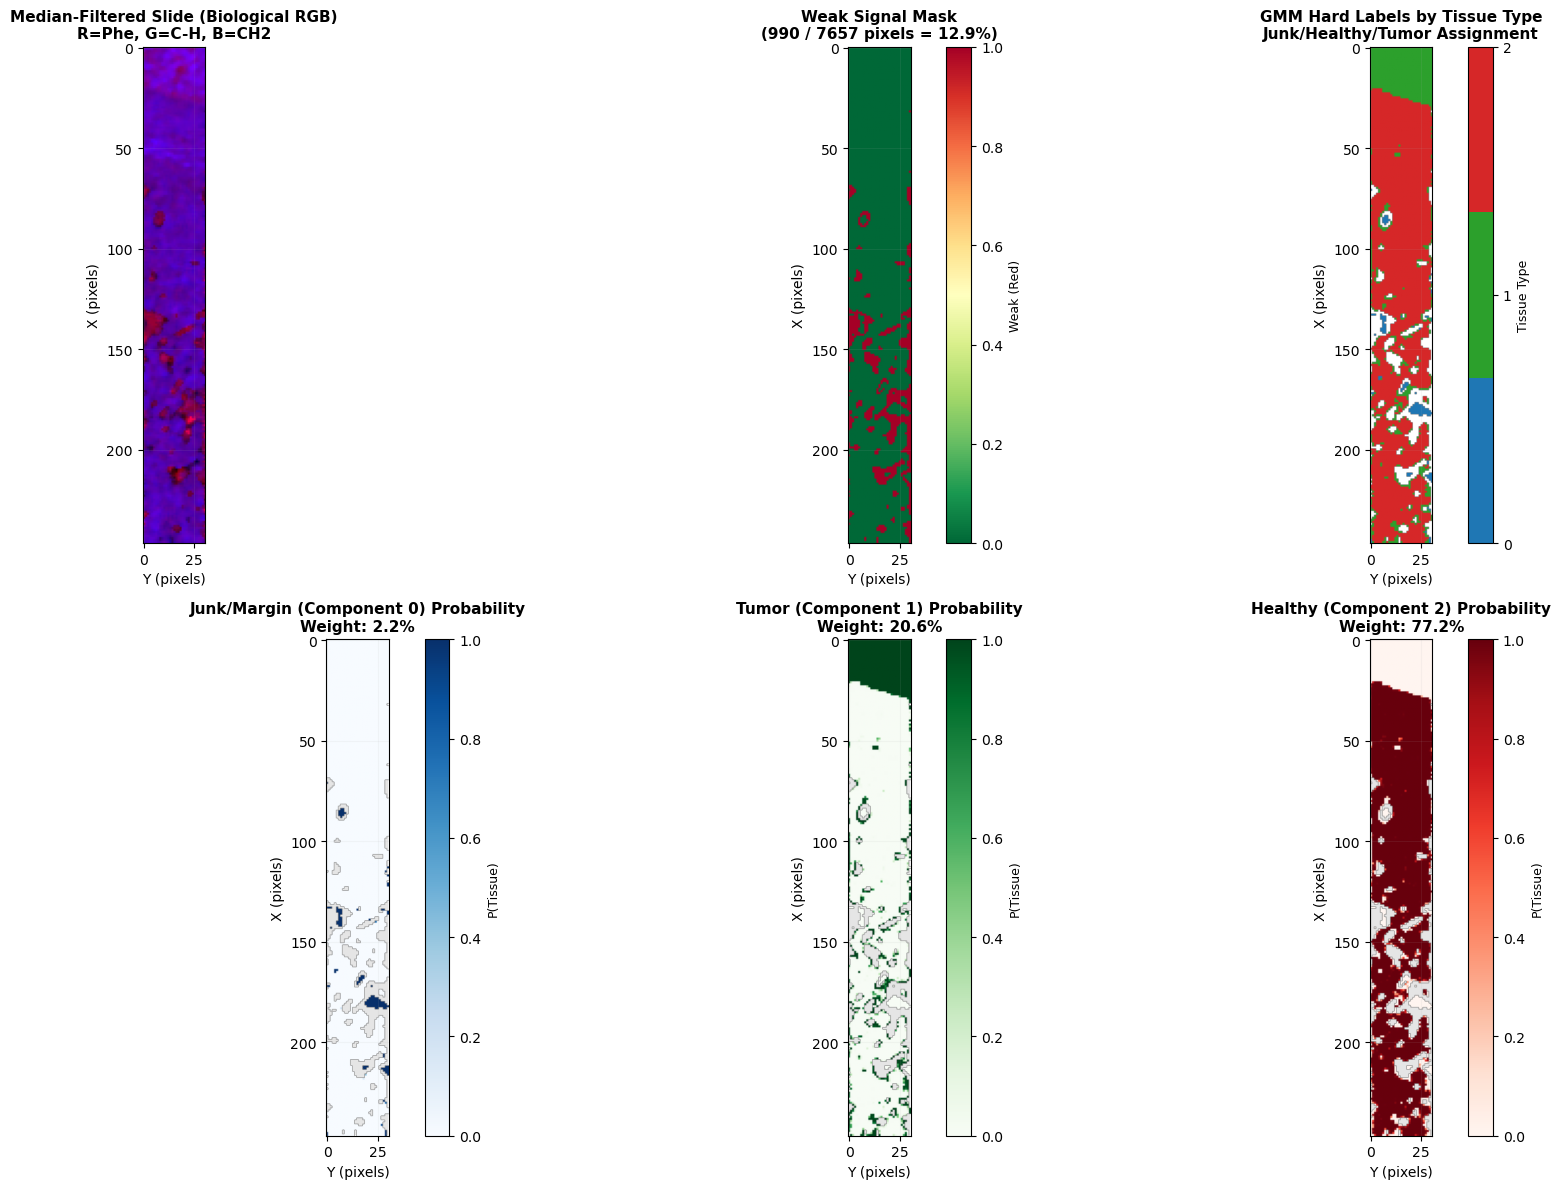


✓ Updated clustering visualization complete!


In [18]:
print("\n" + "="*80)
print("TISSUE TYPE IDENTIFICATION & COLOR MAPPING")
print("="*80)

# Define helper function
def find_wavenumber_index(target_wn, wavenumbers_array):
    """Find the index for a target wavenumber"""
    idx = np.argmin(np.abs(wavenumbers_array - target_wn))
    actual_wn = wavenumbers_array[idx]
    return idx, actual_wn

# Load actual wavenumbers for tissue identification
calib_path = Path("../data/RamanFreqTable.csv")
if calib_path.exists():
    calib_df_freq = pd.read_csv(calib_path)
    wavenumbers_actual = calib_df_freq['freq'].values
    print(f" Loaded wavenumber calibration")
else:
    print(f" Calibration file not found, using spectral indices")
    wavenumbers_actual = np.arange(Lambda)

# Compute metrics for each component
hard_labels_strong = np.argmax(soft_labels, axis=1)
n_pixels_per_component = [np.sum(hard_labels_strong == i) for i in range(3)]
component_mean_spectra = []

print(f"\nComputing mean spectra for tissue identification...")
for comp_idx in range(3):
    mask_comp = hard_labels_strong == comp_idx
    spectra_comp = data_normalized[mask_strong, :][mask_comp, :]
    mean_spectrum = np.mean(spectra_comp, axis=0)
    component_mean_spectra.append(mean_spectrum)
    print(f"  Component {comp_idx}: {n_pixels_per_component[comp_idx]} pixels")

# IDENTIFY TISSUE TYPES
print(f"\nIdentifying tissue types...")

# Junk: Lowest max intensity
max_values = {i: np.max(component_mean_spectra[i]) for i in range(3)}
junk_cluster_id = min(max_values, key=max_values.get)

# Tumor: Highest Phenylalanine (1031 cm⁻¹) + Amide (1208 cm⁻¹) signal
remaining_clusters = [i for i in range(3) if i != junk_cluster_id]
phen_index = find_wavenumber_index(1031, wavenumbers_actual)[0]
amide_index = find_wavenumber_index(1208, wavenumbers_actual)[0]
tumor_cluster_id = max(remaining_clusters, 
                       key=lambda i: component_mean_spectra[i][phen_index] + component_mean_spectra[i][amide_index])

healthy_cluster_id = [i for i in remaining_clusters if i != tumor_cluster_id][0]

print(f"  Junk/Margin: Component {junk_cluster_id}")
print(f"  Healthy: Component {healthy_cluster_id}")
print(f"  Tumor: Component {tumor_cluster_id}")

# Create consistent color and label mappings
component_colors_plot = ['#1f77b4', '#2ca02c', '#d62728']  # Blue, Green, Red
tissue_type_names = {}
tissue_type_names[junk_cluster_id] = "Junk/Margin"
tissue_type_names[healthy_cluster_id] = "Healthy"
tissue_type_names[tumor_cluster_id] = "Tumor"

tissue_labels = {}
tissue_labels[junk_cluster_id] = f"Junk/Margin (n={n_pixels_per_component[junk_cluster_id]})"
tissue_labels[healthy_cluster_id] = f"Healthy (n={n_pixels_per_component[healthy_cluster_id]})"
tissue_labels[tumor_cluster_id] = f"Tumor (n={n_pixels_per_component[tumor_cluster_id]})"

print(f"\n Tissue identification complete!")

# ============================================================================
# UPDATE 2x3 CLUSTERING PLOT WITH TISSUE TYPE LABELS
# ============================================================================
print(f"\n" + "="*80)
print("UPDATING CLUSTERING VISUALIZATION WITH TISSUE TYPE LABELS")
print("="*80)

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

# Top-Left: Biological RGB image
ax = axes[0]
ax.imshow(rgb_normalized)
ax.set_title(f'Median-Filtered Slide (Biological RGB)\nR=Phe, G=C-H, B=CH2', 
             fontsize=11, fontweight='bold')
ax.set_xlabel('Y (pixels)', fontsize=10)
ax.set_ylabel('X (pixels)', fontsize=10)
ax.grid(True, alpha=0.1)

# Top-Middle: Weak signal mask
ax = axes[1]
im = ax.imshow(mask_image, cmap='RdYlGn_r', vmin=0, vmax=1)
ax.set_title(f'Weak Signal Mask\n({n_weak} / {X*Y} pixels = {100*n_weak/(X*Y):.1f}%)', 
             fontsize=11, fontweight='bold')
ax.set_xlabel('Y (pixels)', fontsize=10)
ax.set_ylabel('X (pixels)', fontsize=10)
ax.grid(True, alpha=0.1)
cbar = plt.colorbar(im, ax=ax)
cbar.set_label('Weak (Red)', fontsize=9)

# Top-Right: Hard labels with tissue type identification
ax = axes[2]
component_cmap = ListedColormap(component_colors_plot)
im = ax.imshow(hard_labels_image, cmap=component_cmap, vmin=0, vmax=2)
ax.set_title(f'GMM Hard Labels by Tissue Type\nJunk/Healthy/Tumor Assignment', 
             fontsize=11, fontweight='bold')
ax.set_xlabel('Y (pixels)', fontsize=10)
ax.set_ylabel('X (pixels)', fontsize=10)
ax.grid(True, alpha=0.1)
cbar = plt.colorbar(im, ax=ax, ticks=[0, 1, 2])
cbar.set_label('Tissue Type', fontsize=9)

# Bottom row: Three component probability maps with tissue type labels
component_color_cmaps = ['Blues', 'Greens', 'Reds']
for comp_idx in range(3):
    ax = axes[3 + comp_idx]
    im = ax.imshow(spatial_soft_labels_components[comp_idx], cmap=component_color_cmaps[comp_idx], vmin=0, vmax=1)
    tissue_name = tissue_type_names[comp_idx]
    ax.set_title(f'{tissue_name} (Component {comp_idx}) Probability\nWeight: {gmm.weights_[comp_idx]:.1%}', 
                 fontsize=11, fontweight='bold')
    ax.set_xlabel('Y (pixels)', fontsize=10)
    ax.set_ylabel('X (pixels)', fontsize=10)
    ax.grid(True, alpha=0.1)
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label('P(Tissue)', fontsize=9)
    
    # Add mask overlay to show missing pixels
    missing_mask = np.isnan(spatial_soft_labels_components[comp_idx])
    if np.any(missing_mask):
        ax.contourf(np.arange(Y), np.arange(X), missing_mask.astype(float), 
                    levels=[0.5, 1.5], colors=['gray'], alpha=0.2)

plt.tight_layout()
plt.savefig('gmm_soft_labels_3components_with_tissue_types.png', dpi=100, bbox_inches='tight')
print("\n Saved: gmm_soft_labels_3components_with_tissue_types.png")
plt.show()

print(f"\n Updated clustering visualization complete!")


MEAN SPECTRA PLOT BY TISSUE TYPE

Plotting component mean spectra with tissue type labels...
  Junk/Margin (Component 0): 145 pixels
  Healthy (Component 2): 5173 pixels
  Tumor (Component 1): 1349 pixels

✓ Saved: gmm_component_mean_spectra.png


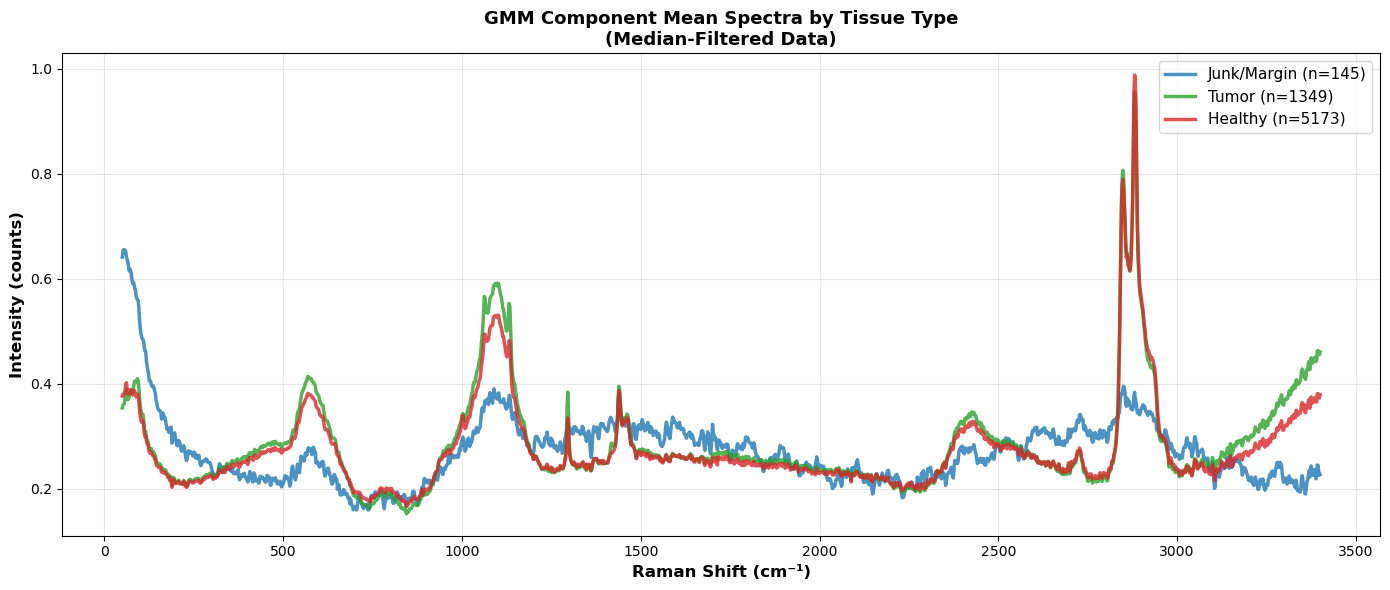


✓ Component mean spectra complete!


In [21]:
print("\n" + "="*80)
print("MEAN SPECTRA PLOT BY TISSUE TYPE")
print("="*80)
print(f"\nPlotting component mean spectra with tissue type labels...")
print(f"  Junk/Margin (Component {junk_cluster_id}): {n_pixels_per_component[junk_cluster_id]} pixels")
print(f"  Healthy (Component {healthy_cluster_id}): {n_pixels_per_component[healthy_cluster_id]} pixels")
print(f"  Tumor (Component {tumor_cluster_id}): {n_pixels_per_component[tumor_cluster_id]} pixels")

# Plot all 3 mean spectra on the same figure with actual Raman shift on X axis
fig, ax = plt.subplots(figsize=(14, 6))

for i in range(3):
    tissue_type = tissue_labels[i]
    ax.plot(wavenumbers_actual, component_mean_spectra[i], 
            color=component_colors_plot[i], linewidth=2.5, 
            label=tissue_type, alpha=0.8)

ax.set_xlabel('Raman Shift (cm⁻¹)', fontsize=12, fontweight='bold')
ax.set_ylabel('Intensity (counts)', fontsize=12, fontweight='bold')
ax.set_title('GMM Component Mean Spectra by Tissue Type\n(Median-Filtered Data)', 
             fontsize=13, fontweight='bold')
ax.legend(fontsize=11, loc='upper right')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('gmm_component_mean_spectra.png', dpi=100, bbox_inches='tight')
print("\n Saved: gmm_component_mean_spectra.png")
plt.show()

print(f"\n Component mean spectra complete!")

In [ ]:
#list directory contents of processed patients and save csv with file names
print(f"\nCurrent directory contents:")
with open('../data/processed/file_names.csv', 'w') as f:
    for item in os.listdir('../data/processed'):
        # if it is a folder write the name to the csv
        if os.path.isdir(os.path.join('../data/processed', item)):
            print(f"  {item}")
            f.write(f"{item}\n")



Current directory contents:
  HF-1002_V1AT_1.h5_0
  HF-1002_V2AT_1.h5_1
  HF-1010_V1T_1.h5_0
  HF-1016_IAT_2.h5_1
  HF-1043_V1AM_1.h5_0
  HF-1086_#1_1.h5_1
  HF-1293_13_1.h5_0
  HF-1295_V3AM_2.h5_1
  HF-1334_V58-B_2_1.h5_2
  HF-1825_V2B_1.h5_2
  HF-1887_via-t_2_1.h5_3
  HF-2070_V1T_1.h5_4
  HF-2102_V2BB_1.h5_3
  HF-2102_V3AM_1.h5_4
  HF-2102_V3AM_2.h5_5
  HF-2104_#5_1.h5_0
  HF-2104_#9_1.h5_1
  HF-2104_V1T_1.h5_2
  HF-2106_V3AM_1.h5_0
  HF-2355_V2AM_1.h5_2
  HF-2454_V1AT_1.h5_6
  HF-2485_V1B_1.h5_3
  HF-2493_V1T_1.h5_1
  HF-2493_V1T_2.h5_2
  HF-2534_V2B_1.h5_2
  HF-2544_V1B_1.h5_3
  HF-2548_V1T_1.h5_7
  HF-2600_V1B_1.h5_4
  HF-2608_V1T_1.h5_5
  HF-2614_V1B_1.h5_3
  HF-2619_V1T_1.h5_6
  HF-2619_V4T_1.h5_7
  HF-2666_V2B_1.h5_8
  HF-2715_VIL_1.h5_8
  HF-2776_V2B_2.h5_5
  HF-2802_V3T_1.h5_9
  HF-2849_VIT2_1.h5_4
  HF-2849_VIT2_1.h5_5
  HF-2849_VIT2_2.h5_6
  HF-2849_VIT_2_new2021.h5_7
  HF-2852_VIT_2_2.h5_8
  HF-2876_V1T_1.h5_10
  HF-2898_V1T_1.h5_11
  HF-305_v4b_1_1.h5_6
  HF-3271_VIB_2.h

In [28]:
# load csv with file names and tumor cluster assignments
file_names_df = pd.read_csv('../data/processed/file_names.csv')
# use is_tumor column from file_names_df, which contains the tumor cluster assignment for each file name, as a list of integers corresponding to cluster ids that are considered tumor (could be 0, 1, or 2 depending on the tissue type identification results)
# load patient_name/hard_labels.npy for each file name and extract clusters. 
# use the tumor cluster ids to create a new mask for each patient that identifies tumor pixels, and save this mask as a new numpy file in the same directory as the original hard_labels.npy file, with the name tumor_mask.npy
for index, row in file_names_df.iterrows():
    file_name = row['patient']
    tumor_cluster_ids = row['is_tumor'] # this should be a list of integers, but if it is a string representation of a list, we need to convert it back to a list. If it is an integer, we can convert it to a list with one element
    if isinstance(tumor_cluster_ids, str):
        tumor_cluster_ids = eval(tumor_cluster_ids)
    elif isinstance(tumor_cluster_ids, int):
        tumor_cluster_ids = [tumor_cluster_ids]
    patient_dir = os.path.join('../data/processed', file_name)
    hard_labels_path = os.path.join(patient_dir, 'hard_labels.npy')
    
    if os.path.exists(hard_labels_path):
        hard_labels = np.load(hard_labels_path)
        tumor_mask = np.isin(hard_labels, tumor_cluster_ids).astype(np.uint8)
        tumor_mask_path = os.path.join(patient_dir, 'tumor_mask.npy')
        np.save(tumor_mask_path, tumor_mask)
        print(f" Processed {file_name}: Tumor mask saved to {tumor_mask_path}")
    else:
        print(f" hard_labels.npy not found for {file_name}, skipping tumor mask creation")

✓ Processed HF-1002_V1AT_1.h5_0: Tumor mask saved to ../data/processed\HF-1002_V1AT_1.h5_0\tumor_mask.npy
✓ Processed HF-1002_V2AT_1.h5_1: Tumor mask saved to ../data/processed\HF-1002_V2AT_1.h5_1\tumor_mask.npy
✓ Processed HF-1010_V1T_1.h5_0: Tumor mask saved to ../data/processed\HF-1010_V1T_1.h5_0\tumor_mask.npy
✓ Processed HF-1016_IAT_2.h5_1: Tumor mask saved to ../data/processed\HF-1016_IAT_2.h5_1\tumor_mask.npy
✓ Processed HF-1043_V1AM_1.h5_0: Tumor mask saved to ../data/processed\HF-1043_V1AM_1.h5_0\tumor_mask.npy
✓ Processed HF-1086_#1_1.h5_1: Tumor mask saved to ../data/processed\HF-1086_#1_1.h5_1\tumor_mask.npy
✓ Processed HF-1293_13_1.h5_0: Tumor mask saved to ../data/processed\HF-1293_13_1.h5_0\tumor_mask.npy
✓ Processed HF-1295_V3AM_2.h5_1: Tumor mask saved to ../data/processed\HF-1295_V3AM_2.h5_1\tumor_mask.npy
✓ Processed HF-1334_V58-B_2_1.h5_2: Tumor mask saved to ../data/processed\HF-1334_V58-B_2_1.h5_2\tumor_mask.npy
✓ Processed HF-1825_V2B_1.h5_2: Tumor mask saved to 

In [29]:
#plot the tumor masks for all patients, save the plots as tumor_masks.png in each patient folder in ../data/processed/{patient}/tumor_masks.png
print(f"\nPlotting tumor masks for all patients...")
for index, row in file_names_df.iterrows():
    file_name = row['patient']
    patient_dir = os.path.join('../data/processed', file_name)
    tumor_mask_path = os.path.join(patient_dir, 'tumor_mask.npy')
    
    if os.path.exists(tumor_mask_path):
        tumor_mask = np.load(tumor_mask_path)
        plt.figure(figsize=(6, 6))
        plt.imshow(tumor_mask, cmap='Reds', vmin=0, vmax=1)
        plt.title(f'Tumor Mask for {file_name}', fontsize=12, fontweight='bold')
        plt.xlabel('Y (pixels)', fontsize=10)
        plt.ylabel('X (pixels)', fontsize=10)
        plt.grid(True, alpha=0.1)
        plt.colorbar(label='Tumor Presence', ticks=[0, 1])
        tumor_mask_plot_path = os.path.join(patient_dir, 'tumor_masks.png')
        plt.savefig(tumor_mask_plot_path, dpi=100, bbox_inches='tight')
        print(f" Saved tumor mask plot for {file_name} to {tumor_mask_plot_path}")
        plt.close()
    else:
        print(f" Tumor mask not found for {file_name}, skipping plot")


Plotting tumor masks for all patients...
✓ Saved tumor mask plot for HF-1002_V1AT_1.h5_0 to ../data/processed\HF-1002_V1AT_1.h5_0\tumor_masks.png
✓ Saved tumor mask plot for HF-1002_V2AT_1.h5_1 to ../data/processed\HF-1002_V2AT_1.h5_1\tumor_masks.png
✓ Saved tumor mask plot for HF-1010_V1T_1.h5_0 to ../data/processed\HF-1010_V1T_1.h5_0\tumor_masks.png
✓ Saved tumor mask plot for HF-1016_IAT_2.h5_1 to ../data/processed\HF-1016_IAT_2.h5_1\tumor_masks.png
✓ Saved tumor mask plot for HF-1043_V1AM_1.h5_0 to ../data/processed\HF-1043_V1AM_1.h5_0\tumor_masks.png
✓ Saved tumor mask plot for HF-1086_#1_1.h5_1 to ../data/processed\HF-1086_#1_1.h5_1\tumor_masks.png
✓ Saved tumor mask plot for HF-1293_13_1.h5_0 to ../data/processed\HF-1293_13_1.h5_0\tumor_masks.png
✓ Saved tumor mask plot for HF-1295_V3AM_2.h5_1 to ../data/processed\HF-1295_V3AM_2.h5_1\tumor_masks.png
✓ Saved tumor mask plot for HF-1334_V58-B_2_1.h5_2 to ../data/processed\HF-1334_V58-B_2_1.h5_2\tumor_masks.png
✓ Saved tumor mask 

In [4]:
"""
Diagnostic script: Check which raw files match their corresponding tumor_masks
Run this to identify mismatches before preprocessing
"""
import numpy as np
from pathlib import Path
import re
import glob

def extract_patient_id(filename):
    match = re.search(r'(HF-\d+)', filename)
    return match.group(1) if match else None

raw_dir = Path("../data/raw")
processed_dir = Path("../data/processed")

# Collect all files and masks
mismatches = []
matches = []

for raw_file in sorted(raw_dir.glob("LGm-*/*.npy")):
    filename = raw_file.name
    patient_id = extract_patient_id(filename)
    
    if not patient_id:
        print(f" Could not extract patient ID from {filename}")
        continue
    
    # Load raw file shape (X, Y, Lambda)
    raw_data = np.load(raw_file)
    raw_shape = raw_data.shape
    raw_xy = (raw_shape[0], raw_shape[1])
    
    # Look for corresponding tumor_mask
    patient_folder = processed_dir / f"{patient_id}*"
    patient_folders = list(processed_dir.glob(f"{patient_id}*"))
    
    if not patient_folders:
        print(f" No processed folder found for {patient_id}")
        continue
    
    # Use first matching folder (should be 1 HF-{id} folder)
    patient_path = patient_folders[0]
    tumor_mask_path = patient_path / "tumor_mask.npy"
    
    if not tumor_mask_path.exists():
        print(f" No tumor_mask.npy for {patient_id}")
        continue
    
    tumor_mask = np.load(tumor_mask_path)
    mask_shape = tumor_mask.shape
    
    if raw_xy == mask_shape:
        matches.append({
            'file': filename,
            'patient': patient_id,
            'raw_shape': raw_xy,
            'mask_shape': mask_shape
        })
        print(f" {filename:45} {raw_xy} == {mask_shape}")
    else:
        mismatches.append({
            'file': filename,
            'patient': patient_id,
            'raw_shape': raw_xy,
            'mask_shape': mask_shape
        })
        print(f" {filename:45} {raw_xy} != {mask_shape}")

print(f"\n{'='*80}")
print(f"SUMMARY:")
print(f"  Matches: {len(matches)}")
print(f"  Mismatches: {len(mismatches)}")
print(f"{'='*80}\n")

if mismatches:
    print("MISMATCHED FILES (raw_shape != mask_shape):")
    print("These files should NOT be processed with their corresponding patient tumor_mask!")
    for m in mismatches:
        print(f"  {m['file']:45} raw={m['raw_shape']} mask={m['mask_shape']} patient={m['patient']}")

✓ HF-1293_13_1.h5_0.npy                         (247, 31) == (247, 31)
✓ HF-1295_V3AM_2.h5_1.npy                       (245, 61) == (245, 61)
✓ HF-2534_V2B_1.h5_2.npy                        (64, 64) == (64, 64)
✓ HF-448_V5B_1.h5_3.npy                         (60, 60) == (60, 60)
✓ HF-868_1_2.h5_4.npy                           (119, 59) == (119, 59)
✓ HF-1010_V1T_1.h5_0.npy                        (60, 60) == (60, 60)
✓ HF-1016_IAT_2.h5_1.npy                        (147, 51) == (147, 51)
✓ HF-1334_V58-B_2_1.h5_2.npy                    (135, 51) == (135, 51)
✓ HF-1887_via-t_2_1.h5_3.npy                    (126, 46) == (126, 46)
✓ HF-2070_V1T_1.h5_4.npy                        (60, 60) == (60, 60)
✓ HF-2776_V2B_2.h5_5.npy                        (147, 52) == (147, 52)
✓ HF-305_v4b_1_1.h5_6.npy                       (121, 51) == (121, 51)
✓ HF-3271_VIB_2.h5_7.npy                        (156, 83) == (156, 83)
✓ HF-3337_V3T_1.h5_8.npy                        (64, 64) == (64, 64)
✓ HF-615_V5BB_1.

In [7]:
"""
Create tumor_maps.npy dict from processed folder structure.

Simple approach: Each processed folder has a tumor_mask.npy.
Create a dict mapping slide_id -> tumor_mask array.

Later in preprocessing.py, we look up by filename key.
"""
import numpy as np
from pathlib import Path

def create_tumor_maps(processed_dir='../data/processed', output_file='../results/exp_102/tumor_maps.npy'):
    """
    Create tumor_maps.npy dict from existing processed folder structure.
    
    For each folder in data/processed/HF-*/, load tumor_mask.npy and add to dict.
    Dict key = slide folder name (e.g., "HF-988_V1-T_1.h5_13")
    Dict value = loaded tumor_mask array
    
    Later in preprocessing, os.path.basename(raw_file) will match the dict key.
    """
    processed_dir = Path(processed_dir)
    output_file = Path(output_file)
    
    print(f"\n{'='*80}")
    print("CREATING tumor_maps.npy FROM PROCESSED FOLDERS")
    print(f"{'='*80}\n")
    
    # Load all tumor_masks from processed folders
    tumor_maps = {}
    
    for slide_folder in sorted(processed_dir.glob("HF-*")):
        mask_file = slide_folder / "tumor_mask.npy"
        
        if mask_file.exists():
            slide_id = slide_folder.name
            tumor_mask = np.load(mask_file)
            tumor_maps[slide_id] = tumor_mask
            
            pct = 100.0 * np.sum(tumor_mask) / tumor_mask.size
            print(f"   {slide_id:50} shape {tumor_mask.shape} ({pct:.1f}% tumor)")
        else:
            print(f"   {slide_folder.name:50} NO tumor_mask.npy")
    
    print(f"\n Loaded {len(tumor_maps)} tumor_masks\n")
    
    # Save dict
    output_file.parent.mkdir(parents=True, exist_ok=True)
    print(f"Saving to {output_file}...")
    np.save(str(output_file), tumor_maps, allow_pickle=True)
    
    print(f" Saved!")
    print(f"  Total entries: {len(tumor_maps)}")
    print(f"  Sample keys: {list(tumor_maps.keys())[:3]}\n")

if __name__ == '__main__':
    create_tumor_maps()


CREATING tumor_maps.npy FROM PROCESSED FOLDERS

  ✓ HF-1002_V1AT_1.h5_0                                shape (60, 60) (76.0% tumor)
  ✓ HF-1002_V2AT_1.h5_1                                shape (64, 64) (100.0% tumor)
  ✓ HF-1010_V1T_1.h5_0                                 shape (60, 60) (89.6% tumor)
  ✓ HF-1016_IAT_2.h5_1                                 shape (147, 51) (93.2% tumor)
  ✓ HF-1043_V1AM_1.h5_0                                shape (64, 64) (99.7% tumor)
  ✓ HF-1086_#1_1.h5_1                                  shape (60, 60) (77.3% tumor)
  ✓ HF-1293_13_1.h5_0                                  shape (247, 31) (17.6% tumor)
  ✓ HF-1295_V3AM_2.h5_1                                shape (245, 61) (15.6% tumor)
  ✓ HF-1334_V58-B_2_1.h5_2                             shape (135, 51) (12.6% tumor)
  ✓ HF-1825_V2B_1.h5_2                                 shape (64, 64) (96.3% tumor)
  ✓ HF-1887_via-t_2_1.h5_3                             shape (126, 46) (18.3% tumor)
  ✓ HF-2070_V1T_1.h5_